##### <img src=../figures/Brown_logo.svg width=50%>

## Data-Driven Design & Analyses of Structures & Materials (3dasm)

## Lecture 19

### Martin van der Schelling | <a href = "mailto: m.p.vanderschelling@tudelft.nl">m.p.vanderschelling@tudelft.nl</a>  | Doctoral Candidate

### Miguel A. Bessa | <a href = "mailto: miguel_bessa@brown.edu">miguel_bessa@brown.edu</a>  | Associate Professor

### Elvis Aguero | <a href = "mailto: elvis_vera@brown.edu">elvis_vera@brown.edu</a>  | PhD candidate

**What:** A lecture of the "3dasm" course

**Where:** This notebook comes from this [repository](https://github.com/bessagroup/3dasm_course)

**Reference for entire course:** Murphy, Kevin P. *Probabilistic machine learning: an introduction*. MIT press, 2022. Available online [here](https://probml.github.io/pml-book/book1.html)

**How:** We try to follow Murphy's book closely, but the sequence of Chapters and Sections is different. The intention is to use notebooks as an introduction to the topic and Murphy's book as a resource.
* If working offline: Go through this notebook and read the book.
* If attending class in person: listen to me (!) but also go through the notebook in your laptop at the same time. Read the book.
* If attending lectures remotely: listen to me (!) via Zoom and (ideally) use two screens where you have the notebook open in 1 screen and you see the lectures on the other. Read the book.

**References/resources to create this notebook:**
* [Car figure](https://korkortonline.se/en/theory/reaction-braking-stopping/)
* [`adda` documentation](https://bessagroup.github.io/adda/)

Apologies in advance if I missed some reference used in this notebook. Please contact me if that is the case, and I will gladly include it here.

## **OPTION 1**. Run this notebook **locally in your computer**:
1. Confirm that you have the '3dasm' mamba (or conda) environment (see Lecture 1).
2. Go to the 3dasm_course folder in your computer and pull the last updates of the [repository](https://github.com/bessagroup/3dasm_course):
```
git pull
```
    - Note: if you can't pull the repo due to conflicts (and you can't handle these conflicts), use this command (with **caution**!) and your repo becomes the same as the one online:
```
git reset --hard origin/main
```
3. Open command window and load jupyter notebook (it will open in your internet browser):
```
jupyter notebook
```
4. Open notebook of this Lecture and choose the '3dasm' kernel.

## **OPTION 2**. Use **Google's Colab** (no installation required, but times out if idle):

1. go to https://colab.research.google.com
2. login
3. File > Open notebook
4. click on Github (no need to login or authorize anything)
5. paste the git link: https://github.com/bessagroup/3dasm_course
6. click search and then click on the notebook for this Lecture.

Colab cannot run the agents of this notebook. You will see the recorded outputs, not new runs. To run a study yourself you need Option 1, with Claude Code installed (see Lecture 10).

In [1]:
# Basic plotting tools needed in Python.
import warnings; warnings.filterwarnings("ignore") # keeps the output of the notebook clean
import json
from pathlib import Path
import matplotlib.pyplot as plt # import plotting tools to create figures
import numpy as np # import numpy to handle a lot of things!
import pandas as pd # to read the data
from IPython.display import SVG, display

%config InlineBackend.figure_format = "retina" # render higher resolution images in the notebook
plt.rcParams["figure.figsize"] = (8,4) # rescale figure size appropriately for slides
pd.set_option('display.max_rows', 10) # To limit the number of rows to show in a dataframe, for presentation purposes

## Outline for today

* `adda`: the agentic layer of `f3dasm`
* The car stopping distance problem as a study
* The smallest team: one agent
* More flexibility:
    - our own tool
    - our own record of the experiments, in `ExperimentData`
    - a model for each agent

**Reading material**: This notebook + the [`adda` documentation](https://bessagroup.github.io/adda/).

## From `f3dasm` to `adda`

<center><img src="../figures/f3dasm_overview.svg" title="f3dasm overview" width="30%"></center>

In Lecture 18 we wrote every block of the data-driven process ourselves: the `Domain`, the sampler, the `DataGenerator`, the models.

`adda` (**A**gentic **D**ata-**D**riven **D**esign and **A**nalysis) is the agentic layer of `f3dasm`. A team of AI agents writes and runs the blocks. We decide:

1. the **problem**, written once in a file
2. the **team**: which agents exist, what each one may do, and who may ask whom
3. how we **check** what comes back

All the agents use **Haiku**, the cheapest model of the course. Doing more with less.

## Five pieces of `adda`

| piece | in `adda` |
|---|---|
| the **study** | a folder with `PROBLEM_STATEMENT.md`, `config.yaml` and the experiment |
| an **agent** | `ClaudeCodeAgent` (plain Claude Code) or `Agent` (our prompt, tools and model) |
| the **team** | `Graph(nodes, edges, entry)` |
| the **run** | `AgenticRun(study_dir, graph).execute()`, which returns the report |
| the **record** | the files the agents wrote, and the measurements as an `ExperimentData` |

Today we build each piece for the car, with a team of one agent. Next lecture, a team of three.

### Installing `adda`

`adda` runs the agents with Claude Code, which you installed for Lecture 10. Install `adda` from GitHub:

```
uv pip install "adda-f3dasm @ git+https://github.com/bessagroup/adda.git"
```

In [2]:
try:
    import adda
except ModuleNotFoundError: # If adda is not found in current environment, install it from GitHub
    %pip install "adda-f3dasm @ git+https://github.com/bessagroup/adda.git" "pymupdf<2" --quiet
    import adda

**Note.** On 2026-10-22, the installation failed with the latest version of `pymupdf` (2.0), a dependency of `adda`. Installing `"pymupdf<2"` in the same command, as in the cell above, fixes it.

## The car stopping distance problem (again!)

<img src="../figures/reaction-braking-stopping.svg" title="Car stopping distance" width="50%" align="right">

In Lecture 18, `compute_distance` was a data generator. Today it is the experiment that the agents run:

* Each call is **one new driver**, and one measurement.
* The agents get at most **30** measurements, and do not know the equation.
* We keep the truth for ourselves: $y = z\,x + 0.1\,x^2$ with $z \sim \mathcal{N}(1.5, 0.5^2)$.

The goal is a model of the mean $\mu(x)$ and of the standard deviation $\sigma(x)$, so that $\mu(x) \pm 1.96\,\sigma(x)$ contains 95% of the new drivers.

## A study is a folder

```
car_solo/
├── PROBLEM_STATEMENT.md     what we want
├── config.yaml              the model and the time budget
└── workspace/
    └── evaluator.py         the experiment: one stop of one new driver
```

`AgenticRun` reads the folder, runs the team, and the agents write their files in it.

In [3]:
Path("car_solo/workspace").mkdir(parents=True, exist_ok=True)

### The experiment, `evaluator.py`

The `compute_distance` of Lecture 18, as a plain function. It also writes every call to `calls.csv`, so that we can count the measurements.

In [4]:
%%writefile car_solo/workspace/evaluator.py
from pathlib import Path
import numpy as np

rng = np.random.default_rng()

def evaluate(x: float) -> float:
    """One new driver at speed x (m/s): the stopping distance in m."""
    y = rng.normal(1.5, 0.5) * x + 0.1 * x ** 2
    with open(Path(__file__).parent / "calls.csv", "a") as f: # keep a record of every call
        f.write(f"{x},{y}\n")
    return float(y)

Overwriting car_solo/workspace/evaluator.py


### The problem statement

The agents work from this file only, so it states precisely the **objective**, the **inputs** with their bounds and units, the **budget**, and the **deliverable**. It does not give the equation.

In [5]:
%%writefile car_solo/PROBLEM_STATEMENT.md
# Stopping distance of a car

A car travelling at speed x (m/s) when its driver first sees an obstacle travels a distance y (m) before it stops.
Different drivers have different reaction times, so repeated measurements at the same speed differ. The equation
behind y is not known.

New measurements come from the evaluator: one call with a speed x in [3, 82] m/s returns the stopping distance y of
one new driver. A measurement is expensive: use at most 30 calls in total.

Goal. Decide at which speeds to measure, and build a model of y as a function of x: its mean mu(x) and its standard
deviation sd(x), such that mu(x) +- 1.96 sd(x) contains about 95% of the stopping distances of new drivers at any
speed in [3, 82] m/s.

Deliverable. A file predict.py with a function predict(x) that takes a speed x in m/s (a float) and returns the pair
(mu, sd) in metres, and a short account of which speeds were measured, why, and the model chosen.

Overwriting car_solo/PROBLEM_STATEMENT.md


### The configuration

* `model`: the model of the agents, Haiku.
* `budget`: the time the run may take.
* `evaluator`: where the experiment is, and the name of its output.

In [6]:
%%writefile car_solo/config.yaml
model: haiku
budget: "00:15:00"
evaluator:
  entrypoint: "workspace/evaluator.py:evaluate"
  output_names: [y]

Overwriting car_solo/config.yaml


## The team is a graph

A team of agents is a **graph**:

* each **node** is an agent
* each **edge** says who may hand work to whom
* the **entry** node receives the problem statement

The smallest team has one node, a `ClaudeCodeAgent`. It is plain Claude Code, the agent of Lecture 10. It needs no configuration.

`render_architecture()` draws the graph, with the model and the tools of each node, without starting any agent.

In [7]:
from adda import Graph, ClaudeCodeAgent

solo = Graph(nodes={"solo": ClaudeCodeAgent(model="haiku")}, # one node, called "solo"
             entry="solo")                                  # it receives the problem statement

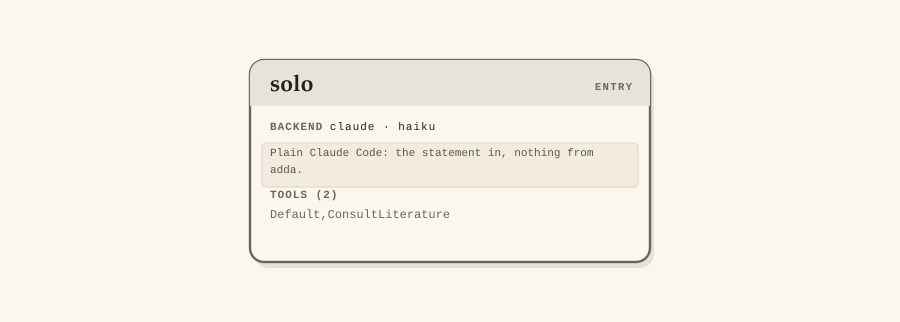

In [8]:
from adda import AgenticRun

run = AgenticRun(study_dir="car_solo", graph=solo, interactive=False, review_statement=False)
display(SVG(filename=run.render_architecture()))

**Note.** `interactive=False` lets the run go on without asking us questions. `review_statement=False` skips the review of the problem statement that `adda` runs before the agents start; the review never changes the statement and is only advice.

## Running the study

`execute()` runs the team and returns the final report of the entry node. Running an agent costs time and money, so we run it **only once**, and save the report in the study folder. The recorded run took 52 s.

In [9]:
study = Path("car_solo")
if not (study / "REPORT.md").exists():     # the agents run only if there is no report yet
    report = run.execute()
    (study / "REPORT.md").write_text(str(report))
print((study / "REPORT.md").read_text())

## ⚠ UNGATED RUN

This run is NOT validated: the run terminated WITHOUT an accepted Done() — the final conclusions did NOT pass the adversarial critic gate.
Treat all conclusions below as unaudited.

---

`predict.py` is written, and the model is fitted from 58 measurements: the 50 already in `data/car_stopping_distance` plus 8 new evaluator calls.

**Which speeds were measured.** I spent 8 of the 30 calls, all at the two ends of the range: four replicates at x = 82 and four at x = 3. The existing data had almost nothing at those ends (one point near 3, none at 82), and the ±1.96 sd band has to hold "at any speed in [3, 82]", so the edges are where the model is least constrained. The replicates agreed with the model at x = 82 (mean ≈ 798 vs. 794 predicted), and at x = 3 they showed more spread than the simple model predicted, which is why I added a constant term to the sd. I did not measure the middle of the range, because the 50 existing points already cover it densely.

**Model.**
- 

### The study folder after the run

In [10]:
sorted(p.name for p in study.iterdir())

['PROBLEM_STATEMENT.md',
 'REPORT.md',
 '__pycache__',
 'architecture.svg',
 'config.yaml',
 'fit_model.py',
 'predict.py',
 'runs',
 'workspace']

## Checking the run against the truth

"The code runs" is not a check (Lecture 10). We load `predict.py`, the deliverable, and compare its band with the truth that only we know.

In [11]:
import importlib.util

def load_predict(path):
    """The function predict(x) -> (mu, sd) that the agents wrote."""
    spec = importlib.util.spec_from_file_location("predict_module", path)
    module = importlib.util.module_from_spec(spec); spec.loader.exec_module(module)
    return module.predict

def plot_against_truth(predict, x_measured, y_measured):
    """The 95% band of a model, the true 95% band, and the measurements."""
    x = np.linspace(3, 82, 200)
    mu, sd = np.array([predict(float(v)) for v in x]).T
    true_mu, true_sd = 1.5 * x + 0.1 * x**2, 0.5 * x
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.fill_between(x, mu - 1.96 * sd, mu + 1.96 * sd, color="b", alpha=0.25, lw=0, label="model")
    ax.plot(x, true_mu - 1.96 * true_sd, "k--", lw=1.5, label="truth")
    ax.plot(x, true_mu + 1.96 * true_sd, "k--", lw=1.5)
    ax.scatter(x_measured, y_measured, s=38, color="r", marker="x", linewidths=1.8, zorder=3)
    ax.set_xlabel("$x$ (m/s)", fontsize=20); ax.set_ylabel("$y$ (m)", fontsize=20)
    ax.legend(loc="upper left", frameon=False, fontsize=15)
    plt.show()

def coverage(predict, n_drivers=2000, seed=0):
    """Fraction of new drivers inside the 95% band of the model, at 60 speeds."""
    x = np.linspace(3, 82, 60)
    mu, sd = np.array([predict(float(v)) for v in x]).T
    drivers = np.random.default_rng(seed).normal(1.5, 0.5, size=(n_drivers, len(x))) * x + 0.1 * x**2
    return np.mean(np.abs(drivers - mu) <= 1.96 * sd)

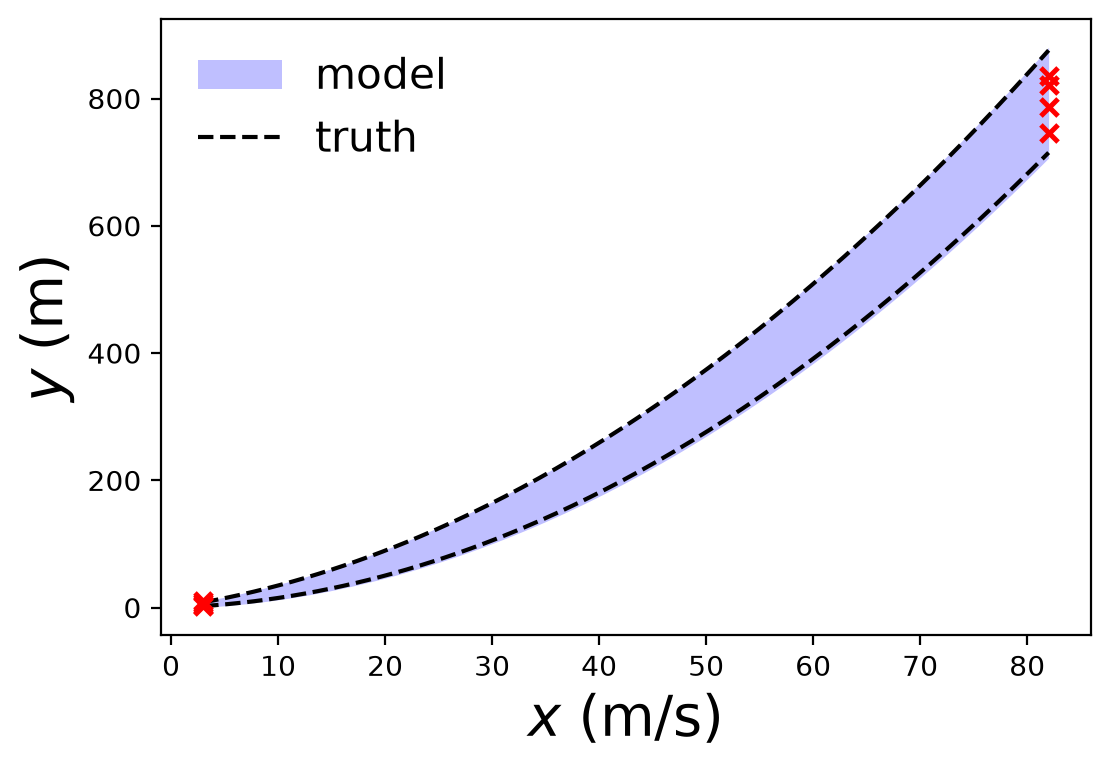

coverage of the band: 0.971


In [12]:
calls = pd.read_csv("car_solo/workspace/calls.csv", header=None, names=["x", "y"]) # every measurement of the run
plot_against_truth(load_predict("car_solo/predict.py"), calls["x"], calls["y"])
print(f"coverage of the band: {coverage(load_predict('car_solo/predict.py')):.3f}")

### The agent sees the whole computer

The report says it. The agent bought only **8** measurements, and fitted its model to **58** stops. It found 50 more in `Lectures/data/car_stopping_distance`, a dataset of another lecture, outside the study folder.

* Everything the agent can reach, it may read and use (files of other folders, and our `calls.csv`, which it can also edit).
* `adda` stores no measurement of a plain Claude Code agent (`evals_used`), but it counts the calls to the evaluator (`raw_solver_calls`):

In [13]:
status = json.load(open(next(study.glob("runs/*/debug/run_status.json"))))
print("calls in calls.csv:              ", len(calls))
print("calls counted by adda:           ", status["raw_solver_calls"])
print("measurements stored by adda:     ", status["evals_used"])

calls in calls.csv:               8
calls counted by adda:            8
measurements stored by adda:      0


## More flexibility: our own tool

An agent acts through its **tools**: `Bash`, `Read`, `Write`... We can give it a tool of our own, written as a **Python function**:

* the **docstring** tells the agent what the tool does
* the **type hints** (`x: float`) tell the agent what to pass
* whatever the function returns, the agent reads

Our tool `Measure` runs the experiment. The equation stays in our notebook, not in a file, and the tool itself refuses a 31st measurement. The statement says where the measurements come from, and our tool is the only place.

In [14]:
rng = np.random.default_rng(0)
measured = {"x": [], "y": []} # our record of every measurement

def Measure(x: float) -> str:
    """Measure the stopping distance y (m) of one new driver at speed x (m/s), with x in [3, 82]. At most 30 calls."""
    if len(measured["x"]) >= 30:
        return "ERROR: all 30 measurements are used."
    if not 3 <= x <= 82:
        return "ERROR: x must be in [3, 82] m/s."
    y = rng.normal(1.5, 0.5) * x + 0.1 * x ** 2
    measured["x"].append(x); measured["y"].append(y)
    return f"y = {y:.3f} m (measurement {len(measured['x'])} of 30)"

**Note.** The budget in `config.yaml` (`eval_budget`) only sends reminders to the agents; it never refuses a measurement. A limit written in the tool is a limit.

### An agent with our tool

`ClaudeCodeAgent` is plain Claude Code and takes no tools from `adda`. For our own tool we write our own agent, an `Agent`:

* `description`: one line that says what the agent does
* `system_prompt`: its instructions
* `tools`: `"Default"` is every tool of Claude Code, and `"Done"` lets it close the run
* `build_closure_tools`: returns our tools, by name

In [15]:
from adda import Agent

class Analyst(Agent):
    description = "Measures stopping distances and builds the model."
    system_prompt = "Solve the problem in PROBLEM_STATEMENT.md. Write predict.py in the study folder. Call Done when predict.py works."
    tools = frozenset({"Default", "Done"})

    def build_closure_tools(self, *args, **kwargs):
        return {"Measure": Measure} # the name the agent sees, and our function

team = Graph(nodes={"analyst": Analyst(model="haiku")}, entry="analyst")

### The study, with the tool

The same statement, but the measurements come from `Measure`, and the folder has no `evaluator.py`. We switch off the machinery of `adda` that this small study does not need (a notebook as deliverable, its reproduction check, and the hypothesis ledger).

In [16]:
Path("car_tool").mkdir(exist_ok=True)
statement = Path("car_solo/PROBLEM_STATEMENT.md").read_text()
Path("car_tool/PROBLEM_STATEMENT.md").write_text(statement.replace(
    "New measurements come from the evaluator: one call with a speed x in [3, 82] m/s returns",
    "New measurements come from the tool Measure: Measure(x) with a speed x in [3, 82] m/s returns"))

947

In [17]:
%%writefile car_tool/config.yaml
model: haiku
budget: "00:15:00"
runtime:
  pipeline_deliverable: false
  reproduction_gate: false
  hypothesis_ledger: false
  verdict_validator: false
  milestones_enabled: false
  science_monitor: false
  peer_interaction: false

Overwriting car_tool/config.yaml


**Note.** Each `runtime` switch is described in the [runtime reference](https://bessagroup.github.io/adda/runtime-reference/). With them on, the agent is also asked for a notebook `pipeline.ipynb` that reproduces its result, and for hypotheses that it must try to falsify. That is useful for a long study and slow for a 30-measurement one.

In [18]:
study = Path("car_tool")
if not (study / "REPORT.md").exists():
    report = AgenticRun(study_dir=study, graph=team, interactive=False, review_statement=False).execute()
    (study / "REPORT.md").write_text(str(report))
    # our record of the measurements, as an f3dasm ExperimentData (Lecture 18)
    from f3dasm import ExperimentData
    from f3dasm.design import Domain
    domain = Domain(); domain.add_float("x", low=3, high=82); domain.add_output("y")
    ExperimentData(domain=domain, input_data=pd.DataFrame({"x": measured["x"]}),
                   output_data=pd.DataFrame({"y": measured["y"]}), project_dir=study).store()
print((study / "REPORT.md").read_text())

predict.py written in the study folder. Used all 30 Measure calls: 13 space-filling speeds across [3,82] (3, 8, 14, 20, 27, 34, 41, 48, 55, 62, 69, 76, 82), 13 gap-fillers (5, 11, 17, 24, 31, 38, 45, 52, 59, 66, 73, 79, 82), plus replicates at 3, 27, 41, 82. Model: mu(x) = 0.09686 x^2 + 1.5557 x (braking plus reaction-distance shape, no intercept); sd(x) = 0.4767 x (scatter grows with speed, consistent with reaction-time variation times speed). In-sample 29/30 points lie within mu +- 1.96 sd; the 30th (x=76, residual about -74 m) is a heavy-tail point. Falsification: compared against a log-log power law (worse fit, residual sd 0.145 in log space) and against constant/affine sd forms; the proportional-to-x sd had the best likelihood and coverage. Remaining uncertainty: only 30 noisy points, so the sd and tails are estimated roughly; extrapolation below 3 m/s is not supported by data. No budget remains to settle these further.


## Our record is an `ExperimentData`

Every measurement went through our tool, so our record is complete, and the agent cannot edit it. We stored it as an `ExperimentData`, and we read it back as in Lecture 18:

In [19]:
from f3dasm import ExperimentData

record = ExperimentData.from_file("car_tool")
x_tool, y_tool = record.to_pandas() # the inputs and the outputs, as pandas tables
print("measurements:", len(record))
record

measurements: 30


,jobs,input,output
,,x,y
0,finished,3,5.588595
1,finished,14,39.675266
2,finished,27,122.045706
3,finished,41,231.750452
4,finished,55,370.269092
...,...,...,...
25,finished,59,439.373363
26,finished,66,510.064525
27,finished,73,608.757024


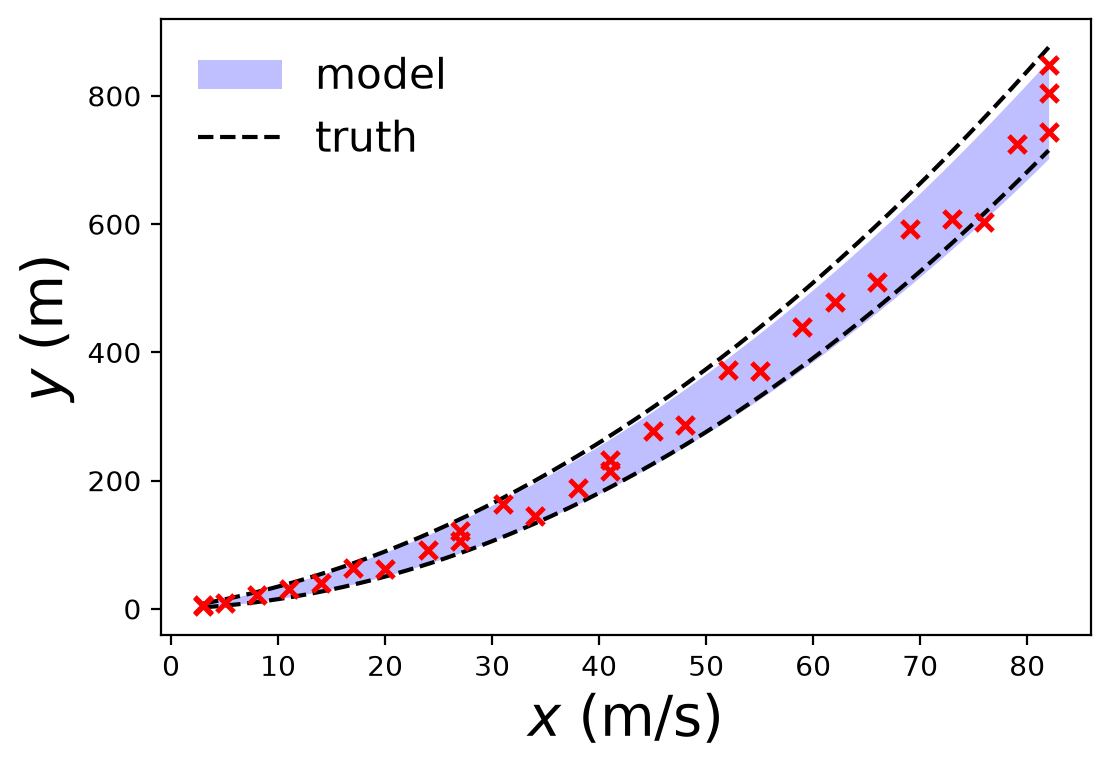

coverage of the band: 0.932


In [20]:
plot_against_truth(load_predict("car_tool/predict.py"), x_tool["x"], y_tool["y"])
print(f"coverage of the band: {coverage(load_predict('car_tool/predict.py')):.3f}")

**Note.** When the agents measure through the evaluator of `config.yaml` with the tools of `adda`, `adda` keeps a record of the same kind, in `runs/<timestamp>/experiment_data/`, with the agent that made each measurement. It loads with `ExperimentData.from_file` as well.

## More flexibility: a model for each agent

Each node has its own model: `Agent(model=...)`. In this course every agent uses Haiku; another node of the same team could use another version of Haiku, or a local model:

```python
Graph(nodes={"builder": ClaudeCodeAgent(model="haiku"),
             "checker": ClaudeCodeAgent(model="claude-haiku-4-5")}, ...)
```

The same can be set in `config.yaml`, without changing the code:

```yaml
nodes:
  checker:
    model: claude-haiku-4-5
```

We use it in the next lecture, where the team has more than one node.

### In-class Exercise 1

Change `Measure` so that it allows only **15** measurements, and run the study again in a new folder `car_tool_15`.

1. How does the band of the model change?
2. What does the agent write about its choice of speeds?

## Summary of today

| | syntax |
|---|---|
| a study | a folder with `PROBLEM_STATEMENT.md` and `config.yaml` |
| plain Claude Code | `ClaudeCodeAgent(model="haiku")` |
| our own agent | `Agent` with `description`, `system_prompt`, `tools` |
| our own tool | a Python function with a docstring, returned by `build_closure_tools` |
| a team | `Graph(nodes={...}, entry=...)` |
| draw it | `AgenticRun(...).render_architecture()` |
| run it | `AgenticRun(...).execute()` |

The agents do the work; the problem, the tools and the checks are ours.

## Field guide: what this lecture adds

### Good practices

**7. Work with an AI coding agent**
- **Check against something you know**, not against "the code runs": e.g. the normal equations, or "the training error cannot increase with the degree".
- **A team of agents is a graph**: each node is an agent with its own prompt, tools and model, and each edge says who may hand work to whom. Start with one node.
- **The statement is the specification**: state the objective, the inputs with bounds and units, the budget, and the deliverables.
- **The agent sees the whole study folder**: keep what it must not read or edit (the truth, your record of the experiments) in your own code, for example in a tool.
- **A limit in a tool is a limit**: the evaluation budget of `config.yaml` (`eval_budget`) only reminds the agents, while a tool can refuse.

The whole [field guide](https://github.com/bessagroup/3dasm_course/blob/main/FIELD_GUIDE.md) collects the key concepts and good practices of every lecture.

### See you next class

Next lecture: a team with more than one agent, and how to make its results checkable.

Have fun!